# *Game over or High Score?*

#### This project analyzes historical video game sales for Ice, an online store that sells games worldwide. Using open data on user and critic reviews, genres, platforms (such as Xbox or PlayStation) and regional sales, the goal is to identify the patterns that make a game successful. These insights will help spot potential best sellers and plan advertising campaigns.

#### The data goes up to 2016. The analysis is set in December 2016, with the aim of planning the campaign for 2017.

## *1. Import and Overview*

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import plotly.express as px
from scipy import stats

In [2]:
games_df = pd.read_csv('datasets\games.csv')
display(games_df.sample(5))
print()
games_df.info()

,Name,Platform,Year_of_Release,Genre,NA_sales,EU_sales,JP_sales,Other_sales,Critic_Score,User_Score,Rating
11622,Happy Feet Two,Wii,NaN,Action,0.06,0.01,0.00,0.01,NaN,NaN,NaN
12111,Motor Toon Grand Prix (Japan),PS,1994.0,Racing,0.00,0.00,0.06,0.00,NaN,NaN,NaN
3697,Ninokuni: Shikkoku no Madoushi,DS,2010.0,Role-Playing,0.00,0.00,0.54,0.00,NaN,NaN,NaN
7215,Naruto Shippuden: Ninja Council 4,DS,2007.0,Action,0.08,0.00,0.13,0.01,49.0,tbd,E10+
16052,Girl Friend Beta: Kimi to Sugosu Natsuyasumi,PSV,2015.0,Action,0.00,0.00,0.02,0.00,NaN,NaN,NaN



<class 'pandas.DataFrame'>
RangeIndex: 16715 entries, 0 to 16714
Data columns (total 11 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Name             16713 non-null  str    
 1   Platform         16715 non-null  str    
 2   Year_of_Release  16446 non-null  float64
 3   Genre            16713 non-null  str    
 4   NA_sales         16715 non-null  float64
 5   EU_sales         16715 non-null  float64
 6   JP_sales         16715 non-null  float64
 7   Other_sales      16715 non-null  float64
 8   Critic_Score     8137 non-null   float64
 9   User_Score       10014 non-null  str    
 10  Rating           9949 non-null   str    
dtypes: float64(6), str(5)
memory usage: 2.0 MB


## *2. Data Cleaning*

#### What needs fixing before the analysis?

A first look at the data showed a few issues. Here's the plan to deal with them, in this order:

1. **Standardize the text.** Column names and text values go to lowercase, with extra spaces removed, so that "FIFA 15" and " fifa 15" count as the same game.
2. **Look for duplicates.** A real duplicate is the same game, on the same platform, showing up twice.
3. **Handle missing values.** Each column gets its own decision: rows are dropped only when very few values are missing, and large gaps stay as NaN.
4. **Deal with "tbd".** In `user_score`, "tbd" means the score was never determined, so it will be treated as missing.
5. **Fix the data types.** `year_of_release` becomes an integer, since years have no decimals, and `user_score` becomes a number so it can be used in calculations. Sales stay as float, because they're in millions and the decimals matter.
6. **Add total sales.** A new column with the sum of all regions.

In [3]:
# Standardizing column names and text values
games_df.columns = games_df.columns.str.lower()

for column in ['name', 'platform', 'genre', 'rating']:
    games_df[column] = games_df[column].str.lower().str.strip()

In [4]:
# Checking unique values

for column in ['name', 'platform', 'genre', 'rating']:
    print(f'{column}: {games_df[column].nunique()} unique values')
    print(games_df[column].dropna().sort_values().unique())
    print()

name: 11559 unique values
<ArrowStringArray>
[                                  ''98 koshien',
                    '.hack//g.u. vol.1//rebirth',
                  '.hack//g.u. vol.2//reminisce',
       '.hack//g.u. vol.2//reminisce (jp sales)',
                 '.hack//g.u. vol.3//redemption',
                       '.hack//infection part 1',
                                   '.hack//link',
                        '.hack//mutation part 2',
                        '.hack//outbreak part 3',
   '.hack//quarantine part 4: the final chapter',
 ...
                                          'zoop',
                                          'zubo',
                                 'zumba fitness',
                               'zumba fitness 2',
                            'zumba fitness core',
                            'zumba fitness rush',
                    'zumba fitness: world party',
                                        'zwei!!',
 'zyuden sentai kyoryuger: game de gaburincho!!',


In [5]:
# Checking duplicates based on name and platform

games_df[games_df.duplicated(subset=['name', 'platform'], keep=False)]

,name,platform,year_of_release,genre,na_sales,eu_sales,jp_sales,other_sales,critic_score,user_score,rating
604,madden nfl 13,ps3,2012.0,sports,2.11,0.22,0.00,0.23,83.0,5.5,e
659,NaN,gen,1993.0,NaN,1.78,0.53,0.00,0.08,NaN,NaN,NaN
1190,need for speed: most wanted,x360,2012.0,racing,0.62,0.78,0.01,0.15,83.0,8.5,t
1591,need for speed: most wanted,x360,2005.0,racing,1.00,0.13,0.02,0.10,83.0,8.5,t
1745,sonic the hedgehog,ps3,2006.0,platform,0.41,0.06,0.04,0.66,43.0,4.1,e10+
4127,sonic the hedgehog,ps3,NaN,platform,0.00,0.48,0.00,0.00,43.0,4.1,e10+
5972,need for speed: most wanted,pc,2005.0,racing,0.02,0.23,0.00,0.04,82.0,8.5,t
11715,need for speed: most wanted,pc,2012.0,racing,0.00,0.06,0.00,0.02,82.0,8.5,t
14244,NaN,gen,1993.0,NaN,0.00,0.00,0.03,0.00,NaN,NaN,NaN
16230,madden nfl 13,ps3,2012.0,sports,0.00,0.01,0.00,0.00,83.0,5.5,e


In [6]:
sales_columns = ['na_sales', 'eu_sales', 'jp_sales', 'other_sales']

games_df.loc[604, sales_columns] += games_df.loc[16230, sales_columns]
games_df.loc[1745, sales_columns] += games_df.loc[4127, sales_columns]

games_df = games_df.drop(index=[16230, 4127]).reset_index(drop=True)

#### What did the duplicates reveal?

Searching for games with the same name and platform brought up a few cases, but not all of them were real duplicates:

* **Need for Speed: Most Wanted** appears twice on X360 and on PC, but with different years (2005 and 2012). These are two different games that share a name, so both stay.
* **Madden NFL 13 and Sonic the Hedgehog (PS3)** were real duplicates. Their sales didn't repeat, they complemented each other: in Sonic's case, one row had most of the North American sales and the other most of the European ones. That looks like a single record split in two, so instead of deleting one row, I summed their sales into one.
* **The two rows without a name** are left for the missing values step, since they don't have a genre either.

In [7]:
# Fixing missing values

games_df = games_df.dropna(subset=['name', 'genre', 'year_of_release']) # Removed because these rows represent around 1.6% of the data
games_df['rating'] = games_df['rating'].fillna('unknown')

#### Why is so much data missing?

Instead of just guessing, I checked a few hypotheses against the data, and three of them clearly hold up:

* **Older games.** Before 2000, almost no game has scores or an ESRB rating. Review sites only became common later, and the ESRB itself was created in 1994.
* **Japan only games.** About 97% of them have no scores and no rating, which makes sense, since the ESRB covers North America.
* **Low sellers.** Among the games that sold the least, 69% have no critic score, against 35% among the best sellers. Smaller games simply get less attention from reviewers.

Two other cases are worth mentioning:

* **"tbd"** shows up mostly in games from 2007 to 2011 with low sales. So it doesn't mean the data is outdated, it means these games never got enough user reviews.
* **Missing years** appear even in well known titles, like Madden NFL 2004 and Call of Duty 3, which points to errors when the data was collected.

Since critic and user scores are missing for about half of the games, dropping those rows would throw away a big part of the dataset, and filling them in would mean inventing scores. So they stay as NaN, which pandas simply ignores in calculations.

In [8]:
# Fixing column data types

games_df['year_of_release'] = games_df['year_of_release'].astype(int)
games_df['user_score'] = pd.to_numeric(games_df['user_score'], errors='coerce') # Also converts "tbd" to NaN

In [9]:
# Adding total_sales column

games_df.insert(8, 'total_sales', games_df[sales_columns].sum(axis=1))

In [10]:
#Fixing incorrect values

games_ds_old=games_df[(games_df['platform']=='ds')&(games_df['year_of_release'] < 2004)]
print(games_ds_old)

                                      name platform  year_of_release   genre  \
15956  strongest tokyo university shogi ds       ds             1985  action   

       na_sales  eu_sales  jp_sales  other_sales  total_sales  critic_score  \
15956       0.0       0.0      0.02          0.0         0.02           NaN   

       user_score   rating  
15956         NaN  unknown  


In [11]:
games_df.loc[(games_df['name'] == 'strongest tokyo university shogi ds') & (games_df['platform'] == 'ds'), 'year_of_release'] = 2007

# The original year (1985) is before the DS launch in 2004. The correct release year is 2007.

In [12]:
display(games_df.sample(5))
print()
games_df.info()

,name,platform,year_of_release,genre,na_sales,eu_sales,jp_sales,other_sales,total_sales,critic_score,user_score,rating
10688,exhibition volume 03,xb,2003,misc,0.07,0.02,0.00,0.0,0.09,NaN,NaN,unknown
15881,disciples iii: renaissance,pc,2010,strategy,0.00,0.01,0.00,0.0,0.01,56.0,5.4,t
8922,yakuza: ishin,ps4,2014,action,0.00,0.00,0.15,0.0,0.15,NaN,NaN,unknown
12022,moxie girlz,ds,2011,misc,0.07,0.00,0.00,0.0,0.07,NaN,NaN,e
12005,pro yaky? spirits 2011,3ds,2011,sports,0.00,0.00,0.07,0.0,0.07,NaN,NaN,unknown



<class 'pandas.DataFrame'>
Index: 16443 entries, 0 to 16712
Data columns (total 12 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   name             16443 non-null  str    
 1   platform         16443 non-null  str    
 2   year_of_release  16443 non-null  int64  
 3   genre            16443 non-null  str    
 4   na_sales         16443 non-null  float64
 5   eu_sales         16443 non-null  float64
 6   jp_sales         16443 non-null  float64
 7   other_sales      16443 non-null  float64
 8   total_sales      16443 non-null  float64
 9   critic_score     7982 non-null   float64
 10  user_score       7462 non-null   float64
 11  rating           16443 non-null  str    
dtypes: float64(7), int64(1), str(4)
memory usage: 2.2 MB


### *So, is the data ready?*

Yes! Here's a quick recap of what changed:

* **Text was standardized**, which also revealed hidden duplicates caused by extra spaces.
* **Two split records** (Madden NFL 13 and Sonic the Hedgehog on PS3) were merged by summing their sales.
* **One wrong date was fixed:** a DS game listed in 1985, years before the console existed, now shows its real release year, 2007.
* **Rows without name, genre or year were removed.** That's about 1.6% of the data, so the impact is small.
* **Missing ESRB ratings became "unknown"**, so these games can still be compared in the regional analysis.
* **Scores were kept as NaN**, including the "tbd" ones, to avoid inventing values.
* **Types were fixed:** `year_of_release` is now an integer and `user_score` a number.
* **A new `total_sales` column** shows each game's sales across all regions.

With that, we can move on to the analysis.

## *3. Exploratory Data Analysis*

#### What makes a game sell?

This is the core of the project. The idea is to go step by step, from the big picture to the details:

1. **How many games came out each year?** And does every period really matter for 2017?
2. **Which platforms sold the most**, and how did their sales change over time?
3. **How long does a platform live?** Which ones used to be popular and are gone now?
4. **Which years should we keep?** Based on the previous answers, pick the period that best represents the 2017 market.
5. **Who's leading now?** Within that period, which platforms are growing and which are fading?
6. **How are sales spread out?** A boxplot of sales per game on each platform.
7. **Do reviews affect sales?** Scores vs sales on a leading platform, then the same check on the others.
8. **Which genres are worth betting on?**

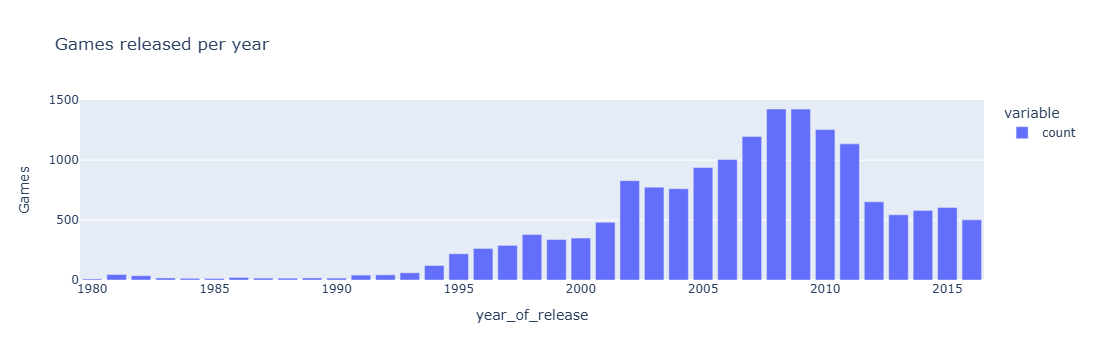

In [13]:
# 3.1. Games per Year:

games_per_year= games_df['year_of_release'].value_counts().sort_index()
px.bar(games_per_year,
       title='Games released per year',
       labels={'index': 'Year', 'value': 'Games'})


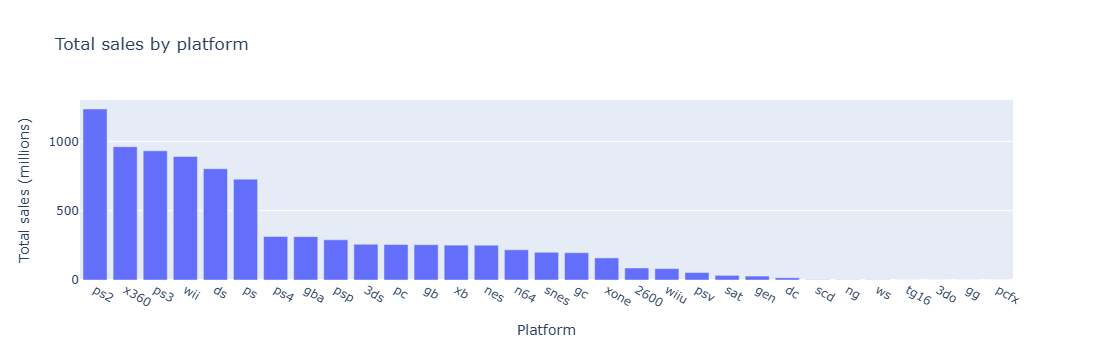

In [14]:
# 3.2.1.Sales by platform
sales_by_platform = games_df.groupby('platform')['total_sales'].sum().sort_values(ascending=False)

px.bar(sales_by_platform, title='Total sales by platform', labels={'platform': 'Platform', 'value': 'Total sales (millions)'}).update_layout(showlegend=False)

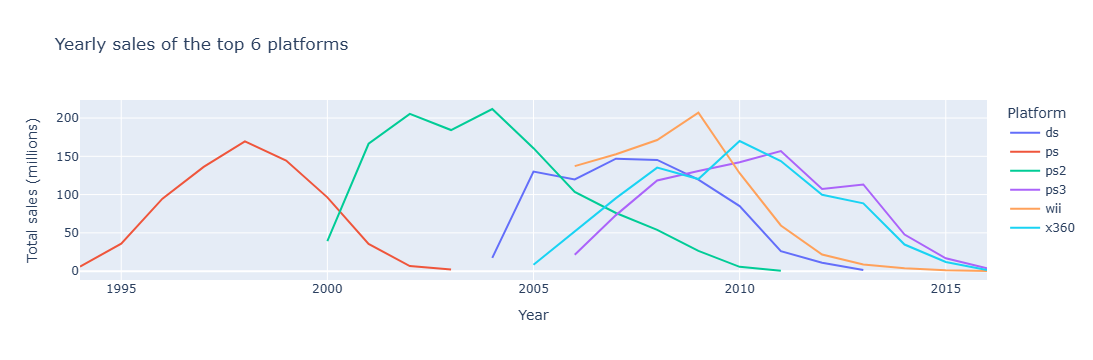

In [15]:
# 3.2.2.Yearly sales of the top 6 platforms

top_platforms = sales_by_platform.head(6).index

top_sales_by_year = games_df[games_df['platform'].isin(top_platforms)].groupby(['platform', 'year_of_release'])['total_sales'].sum().reset_index()

px.line(top_sales_by_year, x='year_of_release', y='total_sales', color='platform',
        title='Yearly sales of the top 6 platforms',
        labels={'year_of_release': 'Year', 'total_sales': 'Total sales (millions)', 'platform': 'Platform'})

In [16]:
# 3.3. Platform Lifecycle

platform_lifecycle = games_df.groupby('platform')['year_of_release'].agg(['min', 'max'])
platform_lifecycle['years_active'] = platform_lifecycle['max'] - platform_lifecycle['min']

display(platform_lifecycle.sort_values('years_active', ascending=False))
print(f"Median years active: {platform_lifecycle['years_active'].median()} years")

ended = platform_lifecycle[platform_lifecycle['max'] < 2016]
print(f"Median years active (ended platforms): {ended['years_active'].median()} years")

,min,max,years_active
platform,,,
pc,1985,2016,31
gb,1988,2001,13
nes,1983,1994,11
psp,2004,2015,11
x360,2005,2016,11
ps2,2000,2011,11
dc,1998,2008,10
ps3,2006,2016,10
wii,2006,2016,10


Median years active: 6.0 years
Median years active (ended platforms): 6.5 years


#### What do the platform charts tell us?

**A few giants dominate.** PS2, X360, PS3, Wii, DS and the original PlayStation lead total sales, and there's a big gap to the next one in line: PS4 has less than half of PlayStation's sales.

**Platforms have a clear life cycle.** Looking at the top six, a platform is born, peaks about 4 to 5 years after launch and then fades. The most successful ones last 10 to 11 years, but a typical platform stays active for only about 6 to 7.

**And they replace each other.** PS was fading as PS2 took off, and PS2 later gave way to PS3. Wii shows how fast it can go: it peaked in 2009 and, by 2011, was selling less than half of that.

Along the way, these charts also exposed a data error: a DS game listed in 1985, almost two decades before the console existed. It was corrected back in the cleaning step.

**What this means for 2017:** old data describes a market that no longer exists, so the campaign should focus on platforms still early in their cycle.

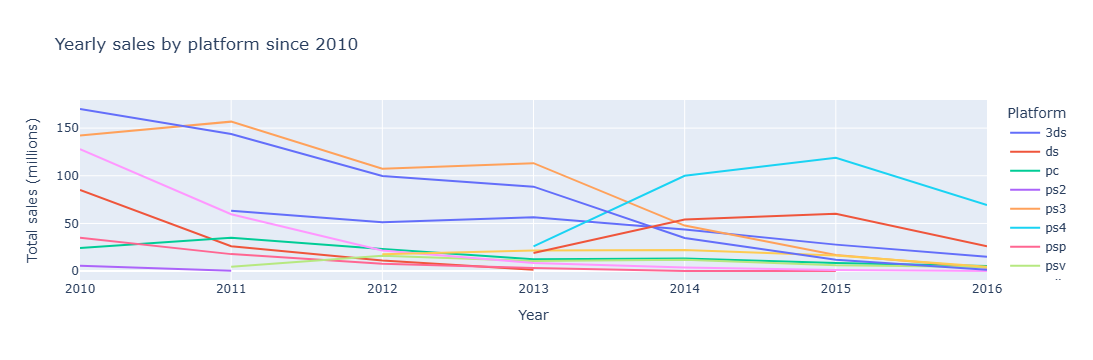

In [17]:
# 3.4.Relevant period

# Checking platform sales since 2010 to choose the relevant period for the 2017 campaign

recent_sales = (games_df[games_df['year_of_release'] >= 2010]
                .groupby(['platform', 'year_of_release'])['total_sales'].sum()
                .reset_index())

px.line(recent_sales, x='year_of_release', y='total_sales', color='platform',
        title='Yearly sales by platform since 2010',
        labels={'year_of_release': 'Year', 'total_sales': 'Total sales (millions)', 'platform': 'Platform'})

#### Which years should we keep?

**From 2013 on.** That's when PS4 and Xbox One were launched, opening the current generation, while PS3, X360 and 3DS started to decline.

Keeping earlier years would give weight to platforms on their way out, which would distort a forecast for 2017. I also considered starting in 2012, which adds the Wii U launch, but it would also bring in the last strong year of PS3 and X360.

One caveat: 2016 data may be incomplete, so a drop in that year doesn't necessarily mean a platform is dying.

platform
ps4     314.14
ps3     181.43
xone    159.32
3ds     143.25
x360    136.80
wiiu     64.63
pc       39.43
psv      32.99
wii      13.66
psp       3.50
ds        1.54
Name: total_sales, dtype: float64

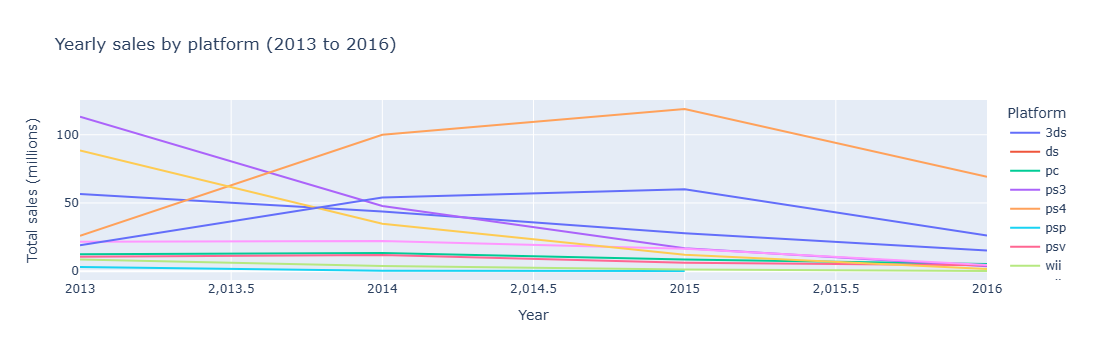

In [18]:
# 3.5.Leading platforms

games_recent = games_df[games_df['year_of_release'] >= 2013]

recent_by_platform = games_recent.groupby('platform')['total_sales'].sum().sort_values(ascending=False)
display(recent_by_platform)

recent_by_year = games_recent.groupby(['platform', 'year_of_release'])['total_sales'].sum().reset_index()

px.line(recent_by_year,
        x='year_of_release',
        y='total_sales',
        color='platform',
        title='Yearly sales by platform (2013 to 2016)',
        labels={'year_of_release': 'Year', 'total_sales': 'Total sales (millions)', 'platform': 'Platform'})

#### Who's leading the current generation?

**PS4 is the clear winner.** It has the highest sales in the period by a wide margin and is still near its peak.

**Xbox One comes next** as the second strongest platform of the new generation.

**PS3 is a trap.** It still shows one of the highest totals, but that comes mostly from 2013, and its sales have been falling fast ever since. The same goes for X360.

**Being new doesn't guarantee success.** Wii U launched in 2012, but its sales are low and already declining.

**3DS is fading, but not gone**, and may still matter in specific regions.

**What this means for 2017:** the most promising platforms are PS4, Xbox One and, depending on the region, 3DS.

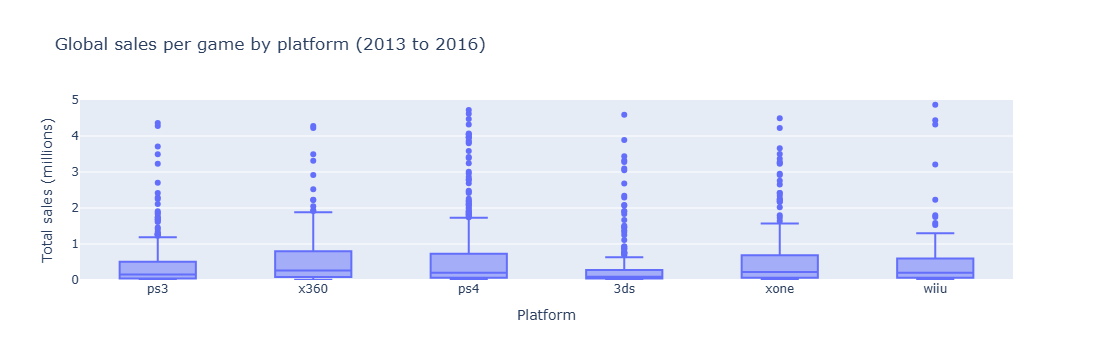

In [19]:
# 3.6.Sales distribution

top_recent = recent_by_platform.head(6).index

px.box(games_recent[games_recent['platform'].isin(top_recent)],
x='platform', y='total_sales',
title='Global sales per game by platform (2013 to 2016)',
labels={'platform': 'Platform', 'total_sales': 'Total sales (millions)'}).update_yaxes(range=[0, 5])

#### How are sales spread out?

**Most games sell very little.** On every platform the box sits low: half of PS4 games, for example, sell less than about 200 thousand copies.

**The typical game sells about the same everywhere.** Medians are similar across platforms, and X360 and Xbox One are even slightly above PS4.

**The hits make the difference.** What really separates the platforms are the outliers, those dots above the boxes. PS4 has the most hits, with a single game selling over 14 million copies, and that's what drives its lead.

*Note: the chart is zoomed in for readability, so the biggest hits sit above the visible area.*

**What this means for 2017:** a platform's total says more about its hits than about its typical game, so picking the right titles matters as much as picking the platform.

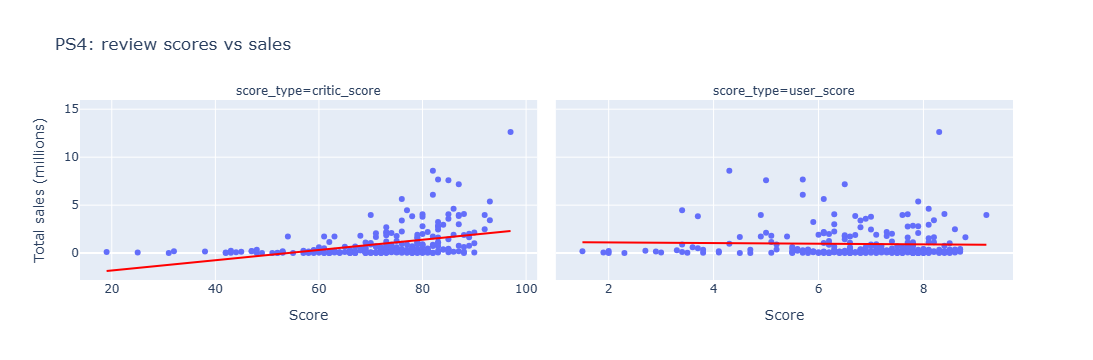

,critic_score,user_score,total_sales
critic_score,1.000000,0.557654,0.406568
user_score,0.557654,1.000000,-0.031957
total_sales,0.406568,-0.031957,1.000000


In [20]:
# 3.7. Do the reviews affect the sales? 

ps4_games = games_recent[games_recent['platform'] == 'ps4']

ps4_scores = ps4_games.melt(id_vars='total_sales', value_vars=['critic_score', 'user_score'],
var_name='score_type', value_name='score')

fig = px.scatter(ps4_scores, x='score', y='total_sales', facet_col='score_type', trendline='ols',
                 trendline_color_override='red',
                 title='PS4: review scores vs sales',
                 labels={'score': 'Score', 'total_sales': 'Total sales (millions)'})
fig.update_xaxes(matches=None)
fig.show()


display(ps4_games[['critic_score', 'user_score', 'total_sales']].corr())

#### So, do the reviews affect the sales?

To answer this, I looked at PS4, the leading platform of the period, and compared its sales with both critic and user scores.

**Critics seem to matter, at least a bit.** The correlation between critic score and sales is 0.41. Games that critics like tend to sell more, but a good score alone doesn't make a hit: there are plenty of well reviewed games with modest sales.

**Users, surprisingly, don't.** The correlation between user score and sales is basically zero (-0.03). In other words, what players rate a game says almost nothing about how much it sells.

**Critics and users partly agree.** Their scores have a correlation of 0.56, so they usually point in the same direction, just not always.

**What this means for 2017:** critic reviews are a useful signal when choosing which games to promote, while user scores shouldn't weigh much in that decision.

In [21]:
# what if we compare to other platforms?

platform_corr = (games_recent[games_recent['platform'].isin(top_recent)]
                 .groupby('platform')[['critic_score', 'user_score', 'total_sales']]
                 .corr()['total_sales']
                 .unstack()
                 .drop(columns='total_sales'))
display(platform_corr)

,critic_score,user_score
platform,,
3ds,0.357057,0.241504
ps3,0.334285,0.002394
ps4,0.406568,-0.031957
wiiu,0.376415,0.419330
x360,0.350345,-0.011742
xone,0.416998,-0.068925


#### And what if we compare to other platforms?

PS4 could be an exception, so I ran the same correlations for the six leading platforms.

**Critics matter everywhere.** On every platform, the correlation between critic score and sales stays between 0.33 and 0.42. It's never strong, but it's consistent: well reviewed games tend to sell a bit more, no matter the console.

**Users only matter on Nintendo.** On PlayStation and Xbox, user scores have basically no relation to sales. On Nintendo it's different: the correlation reaches 0.24 on 3DS and 0.42 on Wii U, even higher than the critics.

**Nintendo players seem to trust each other.** Even though Wii U isn't a big seller, its audience clearly follows what other players think when deciding what to buy.

**What this means for 2017:** when choosing which games to promote, critic scores are a reliable signal across all platforms, and on Nintendo platforms, user scores are worth checking too.

,sum,median,count
genre,,,
shooter,232.98,0.450,187
sports,150.65,0.240,214
platform,42.63,0.225,74
role-playing,145.89,0.125,292
fighting,35.31,0.125,80
racing,39.89,0.120,85
action,321.87,0.110,766
simulation,21.76,0.100,62
misc,62.82,0.100,155


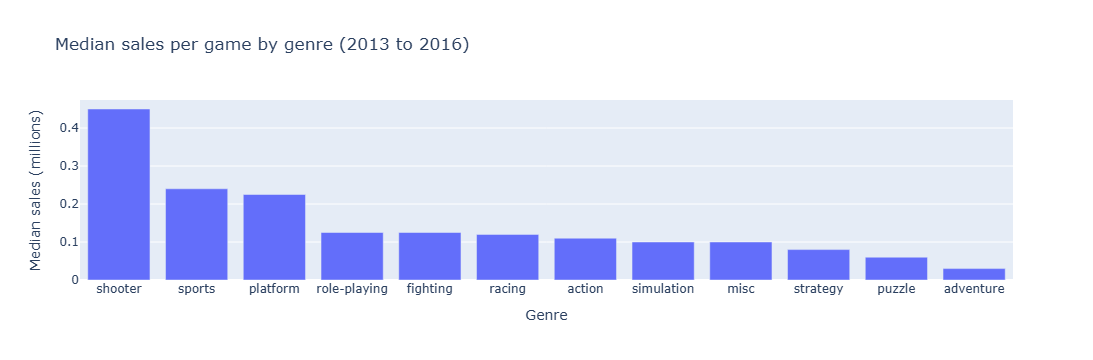

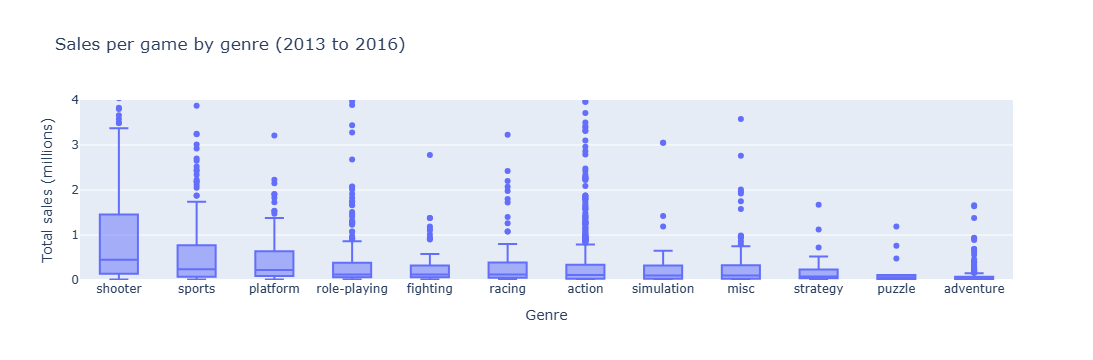

In [26]:
# 3.8. Which genres are worth betting on?

genre_sales = (games_recent.groupby('genre')['total_sales']
               .agg(['sum', 'median', 'count'])
               .sort_values('median', ascending=False))
display(genre_sales)

px.bar(genre_sales.reset_index(), x='genre', y='median',
       title='Median sales per game by genre (2013 to 2016)',
       labels={'genre': 'Genre', 'median': 'Median sales (millions)'}).show()

px.box(games_recent, x='genre', y='total_sales',
       title='Sales per game by genre (2013 to 2016)',
       labels={'genre': 'Genre', 'total_sales': 'Total sales (millions)'},
       category_orders={'genre': genre_sales.index.tolist()}).update_yaxes(range=[0, 4]).show()

#### Which genres are worth betting on?

At first glance, **action** looks like the obvious winner: it has the highest total sales (322 million) and by far the most games (766). But that's exactly the catch. With so many releases, a few big hits push the total up, while the typical action game sells only about 110 thousand copies.

That's why I looked at the **median sales per game** instead of just the total. The median shows how much a typical game sells, without being distorted by a handful of blockbusters.

**Shooters stand out.** A typical shooter sells about 450 thousand copies, almost twice as much as the next genre. Fewer games, but a much better chance of each one selling well. The boxplot confirms it: the shooter box sits clearly higher than the rest, while action has many outliers above a low box.

**Sports and platform come next**, both around 230 thousand per game.

**Adventure is the riskiest bet:** 245 games, but the typical one sells only 30 thousand copies.

**What this means for 2017:** action is the biggest market, but also the most crowded. For a safer bet, shooters, sports and platform games offer better sales per title.